# Практична робота №4
Методи регресійного аналізу

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Завантаження даних з файлу Advertising.csv
df = pd.read_csv('Advertising.csv', sep=',')
display(df.head())

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


### Побудова ліній регресії з 95% довірчим інтервалом

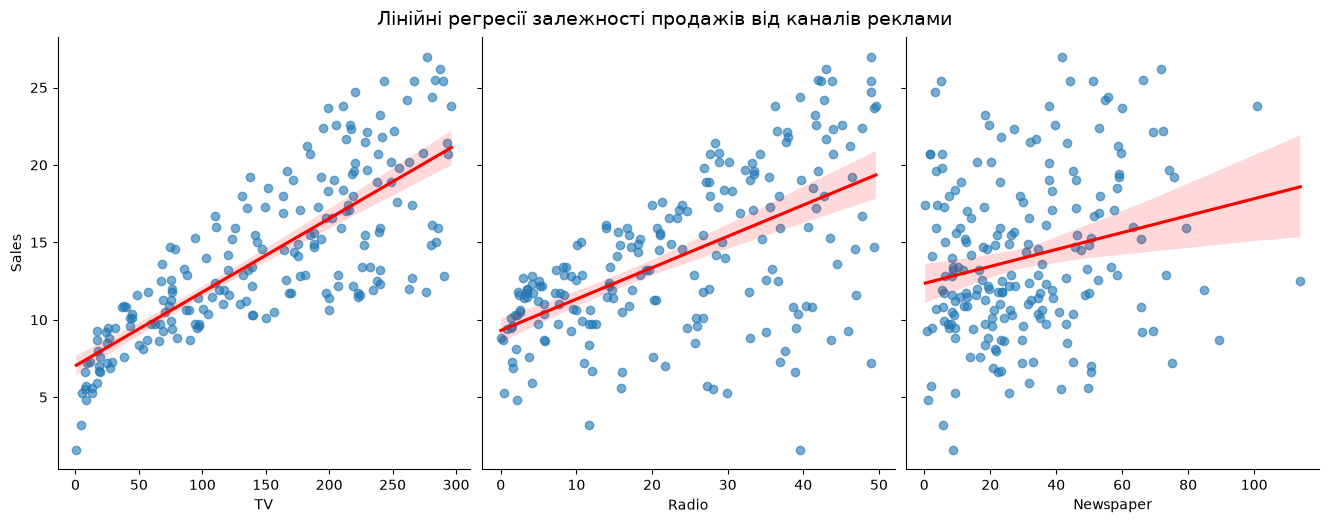

In [4]:
sns.pairplot(
    df, 
    x_vars=['TV', 'Radio', 'Newspaper'], 
    y_vars='Sales', 
    height=5, 
    aspect=0.9, 
    kind='reg',
    plot_kws={'line_kws': {'color': 'red'}, 'scatter_kws': {'alpha': 0.6}}
)
plt.suptitle("Лінійні регресії залежності продажів від каналів реклами", y=1.03, fontsize=14)
plt.show()

### Коробчасті діаграми (Boxplot) для даних TV, Radio і Newspaper

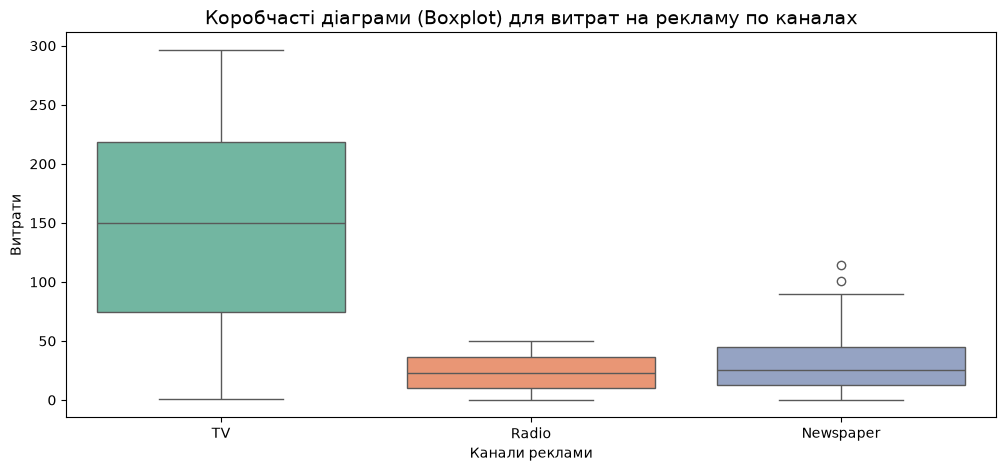

In [5]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[['TV', 'Radio', 'Newspaper']], palette="Set2")
plt.title('Коробчасті діаграми (Boxplot) для витрат на рекламу по каналах', fontsize=14)
plt.ylabel('Витрати')
plt.xlabel('Канали реклами')
plt.show()

### Оцінка модельних коефіцієнтів для реклами в газетах і на радіо

In [6]:
# Модель для реклами на радіо (Radio -> Sales)
lm_radio = smf.ols(formula='Sales ~ Radio', data=df).fit()
print("--- Коефіцієнти для моделі Sales ~ Radio ---")
print(lm_radio.params)
print("\n")

# Модель для реклами в газетах (Newspaper -> Sales)
lm_newspaper = smf.ols(formula='Sales ~ Newspaper', data=df).fit()
print("--- Коефіцієнти для моделі Sales ~ Newspaper ---")
print(lm_newspaper.params)

--- Коефіцієнти для моделі Sales ~ Radio ---
Intercept    9.311638
Radio        0.202496
dtype: float64


--- Коефіцієнти для моделі Sales ~ Newspaper ---
Intercept    12.351407
Newspaper     0.054693
dtype: float64


### Прогнозування продажів
- Якщо на рекламу на радіо буде витрачено $24 тис.
- Якщо на рекламу в газеті буде витрачено $15 тис.

In [7]:
X_new_radio = pd.DataFrame({'Radio': [24]})
X_new_newspaper = pd.DataFrame({'Newspaper': [15]})

pred_radio = lm_radio.predict(X_new_radio)
pred_newspaper = lm_newspaper.predict(X_new_newspaper)

print(f"Прогнозовані продажі при витратах на Radio ($24 тис.): {pred_radio.values[0]:.4f}")
print(f"Прогнозовані продажі при витратах на Newspaper ($15 тис.): {pred_newspaper.values[0]:.4f}")

Прогнозовані продажі при витратах на Radio ($24 тис.): 14.1715
Прогнозовані продажі при витратах на Newspaper ($15 тис.): 13.1718
